定位算法对比 (G=1600)
生成非均匀网格 (G=1600)...
网格生成完成，共 1600 个点。
网格生成耗时: 0.01s

初始化 DSB Localizer...
计算阵列流形矩阵...
计算相关矩阵 (这可能需要几秒钟)...
初始化 Neal Localizer...
计算阵列流形矩阵...
计算相关矩阵 (这可能需要几秒钟)...

开始计算 100 个位置点...
进度 10/100 | DSB均误: 8.55m | Neal均误: 2.35m
进度 20/100 | DSB均误: 7.97m | Neal均误: 2.34m
进度 30/100 | DSB均误: 7.35m | Neal均误: 2.44m
进度 40/100 | DSB均误: 6.65m | Neal均误: 2.15m
进度 50/100 | DSB均误: 6.04m | Neal均误: 1.91m
进度 60/100 | DSB均误: 5.65m | Neal均误: 1.80m
进度 70/100 | DSB均误: 5.47m | Neal均误: 1.70m
进度 80/100 | DSB均误: 5.46m | Neal均误: 1.68m
进度 90/100 | DSB均误: 5.62m | Neal均误: 1.71m
进度 100/100 | DSB均误: 5.93m | Neal均误: 1.84m
总耗时: 690.39 秒


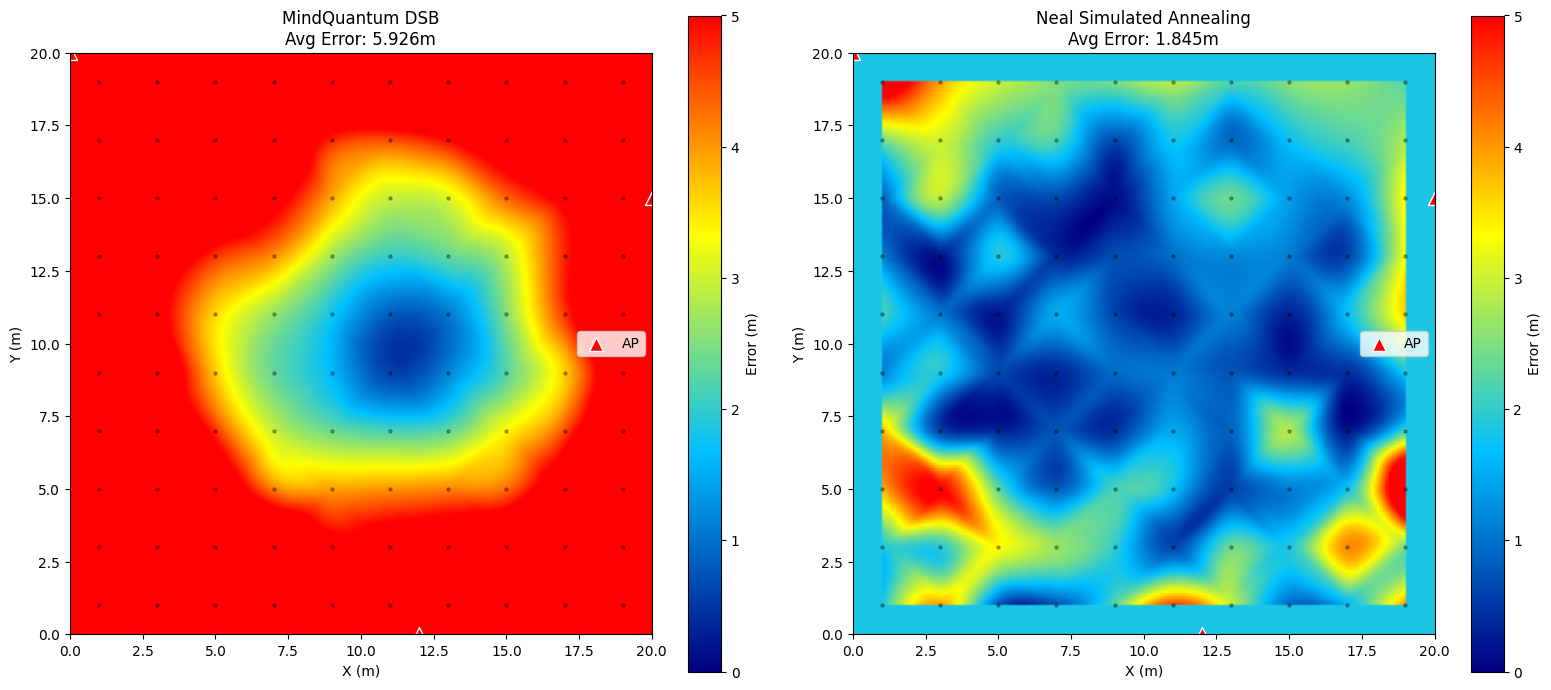

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import speed_of_light
from scipy.sparse import csr_matrix
import time
import neal
import dimod
from matplotlib.colors import LinearSegmentedColormap
from scipy.interpolate import griddata
import warnings


warnings.filterwarnings('ignore')


# ==========================================
# 1. 交替投影法生成非均匀网格 (G=1600)
# ==========================================
def alternating_projection_grid_design(ap_positions, G=900, M=10, d=0.087, fc=2.4e9):

    print(f"生成非均匀网格 (G={G})...")

    x_min, x_max, y_min, y_max = 0, 20, 0, 20

    # 1. 基础均匀采样池 (比目标G多很多，用于重采样)
    pool_size = G * 10
    pool = np.random.rand(pool_size, 2)
    pool[:, 0] = pool[:, 0] * (x_max - x_min) + x_min
    pool[:, 1] = pool[:, 1] * (y_max - y_min) + y_min

    # 2. 计算密度概率 (靠近AP概率高)
    density = np.zeros(pool_size)
    for ap in ap_positions:
        distances = np.sqrt((pool[:, 0] - ap[0]) ** 2 + (pool[:, 1] - ap[1]) ** 2)
        # Sigma控制聚集程度，6.0表示覆盖范围较广
        density += np.exp(-(distances**2) / (2 * 6.0**2))

    density = density / np.sum(density)

    # 3. 依概率重采样得到最终网格
    indices = np.random.choice(pool_size, size=G, p=density, replace=False)
    grid_points = pool[indices]

    print(f"网格生成完成，共 {len(grid_points)} 个点。")
    return grid_points


# ==========================================
# 2. 基础物理与信号模型 ，如之前一样
# ==========================================
def nearfield_array_manifold(theta, r, M, d, wavelength):
    m_idx = np.arange(M)
    safe_r = np.maximum(r, 1e-4)
    # 向量化计算相位
    phase = -2 * np.pi * d * m_idx * np.sin(theta) / wavelength + np.pi * (m_idx**2) * (d**2) * np.cos(
        theta
    ) ** 2 / (wavelength * safe_r)
    a = np.exp(1j * phase)
    return a / np.linalg.norm(a)


def generate_ap_signal(true_pos, ap_pos, M, d, fc, n_clusters=2, n_paths=3, SNR_DB=20):
    wavelength = speed_of_light / fc
    dx, dy = true_pos[0] - ap_pos[0], true_pos[1] - ap_pos[1]
    r_los = np.hypot(dx, dy)
    theta_los = np.arctan2(dy, dx)
    theta_los += np.pi if dx < 0 else 0

    # 主径 (LoS)
    a_los = nearfield_array_manifold(theta_los, r_los, M, d, wavelength)

    # 路径损耗 ，有所简化
    pl_linear = 10 ** (-(40 + 20 * np.log10(r_los + 1e-6)) / 10)

    # 信号模型：主径 + 随机相位

    y = np.sqrt(pl_linear) * np.exp(1j * 2 * np.pi * np.random.rand()) * a_los

    # 多径分量 (模拟反射)
    for _ in range(n_clusters):
        dst = r_los + np.random.uniform(2, 10)
        ang = theta_los + np.random.uniform(-0.5, 0.5)
        a_mp = nearfield_array_manifold(ang, dst, M, d, wavelength)
        pl_mp = 10 ** (-(40 + 25 * np.log10(dst + 1e-6)) / 10)
        y += np.sqrt(pl_mp) * (np.random.randn() + 1j * np.random.randn()) / np.sqrt(2) * a_mp

    # 添加高斯白噪声
    sig_power = np.sum(np.abs(y) ** 2) / M
    noise_power = sig_power / (10 ** (SNR_DB / 10))
    noise = np.sqrt(noise_power / 2) * (np.random.randn(M) + 1j * np.random.randn(M))

    return (y + noise)[:, None]


def generate_all_signals(true_pos, ap_positions, params):
    return [
        generate_ap_signal(
            true_pos,
            ap,
            params['M'],
            params['d'],
            params['fc'],
            params['n_clusters'],
            params['n_paths'],
            params['SNR_DB'],
        )
        for ap in ap_positions
    ]


# ==========================================
# 3. DSB算法
# ==========================================
class DSB:
    def __init__(self, J, h, n_iter=80, batch_size=50, dt=0.5, temperature=0.2):
        # 归一化 Ising 参数，防止梯度爆炸
        max_val = max(np.max(np.abs(J)), np.max(np.abs(h)), 1e-9)
        self.J_raw = csr_matrix(J / max_val)
        self.h_raw = (h / max_val).reshape(-1, 1)

        self.N = J.shape[0]
        self.n_iter = n_iter
        self.batch_size = batch_size
        self.dt = dt
        self.temperature = temperature
        self.xi = 0.5 / np.sqrt(self.N)

        self.initialize()

    def initialize(self):
        self.x = 2 * (np.random.rand(self.N, self.batch_size) - 0.5)
        self.y = np.random.randn(self.N, self.batch_size) * 0.1

    def update(self):
        for i in range(self.n_iter):
            t_factor = 1 - i / self.n_iter
            curr_temp = self.temperature * t_factor

            sig_x = np.tanh(self.x)
            interaction = self.J_raw.dot(sig_x)
            force = interaction + self.h_raw - self.x
            noise = np.random.randn(self.N, self.batch_size) * np.sqrt(curr_temp)

            self.y = 0.9 * self.y + force * self.dt + noise
            self.x += self.y * self.dt
            np.clip(self.x, -1.5, 1.5, out=self.x)

    def get_best_solution(self):
        final_state = np.sign(self.x)
        final_state[final_state == 0] = 1

        # 计算能量选最好的
        energies = np.zeros(self.batch_size)
        for b in range(self.batch_size):
            s = final_state[:, b]
            e = -0.5 * s.dot(self.J_raw.dot(s)) - self.h_raw.flatten().dot(s)
            energies[b] = e

        return (final_state[:, np.argmin(energies)] + 1) / 2


# ==========================================
# 4. 定位器基类
# ==========================================
class BaseLocalizer:
    def __init__(self, ap_positions, grid_points, M=10, d=0.087, fc=2.4e9):
        self.ap_positions = ap_positions
        self.grid_points = grid_points
        self.G = len(grid_points)
        self.P = len(ap_positions)
        self.M = M
        self.d = d
        self.fc = fc
        self.wavelength = speed_of_light / fc

        print("计算阵列流形矩阵...")
        self.psi_matrices = self._build_psi_matrices()

        print("计算相关矩阵 (这可能需要几秒钟)...")
        self.CrossCorr = np.zeros((self.G, self.G))
        for p in range(self.P):
            Psi = self.psi_matrices[p]
            # 计算相关性矩阵 GxG
            self.CrossCorr += np.real(Psi.conj().T @ Psi)

        # 归一化相关矩阵
        diag_max = np.max(np.diag(self.CrossCorr))
        if diag_max > 0:
            self.CrossCorr /= diag_max

    def _build_psi_matrices(self):
        psi_list = []
        for ap in self.ap_positions:
            dx = self.grid_points[:, 0] - ap[0]
            dy = self.grid_points[:, 1] - ap[1]
            th = np.arctan2(dy, dx)
            th += np.pi * (dx < 0)
            r = np.hypot(dx, dy)

            Psi_ap = np.zeros((self.M, self.G), dtype=complex)
            for g in range(self.G):
                Psi_ap[:, g] = nearfield_array_manifold(th[g], r[g], self.M, self.d, self.wavelength)
            psi_list.append(Psi_ap)
        return psi_list

    def _compute_linear_coeffs(self, y_obs):
        """
        计算观测信号与网格点的匹配度。
        关键点：使用 abs() 而非 real() 以消除随机相位影响。
        """
        linear_coeffs = np.zeros(self.G)
        for p, y in enumerate(y_obs):
            y = y / (np.linalg.norm(y) + 1e-9)
            projection = y.conj().T @ self.psi_matrices[p]
            linear_coeffs += np.abs(projection).flatten()
        return linear_coeffs


# ==========================================
# 5. MindQuantum (DSB) 定位器
# ==========================================
class MindQuantumLocalizer(BaseLocalizer):
    def localize(self, y_obs, gamma=0.6):
        linear = self._compute_linear_coeffs(y_obs)
        if np.max(linear) > 0:
            linear /= np.max(linear)

        # 构建 Ising 矩阵
        # 对角项包含自相关惩罚和线性奖励
        # 增加 linear 的权重 (3.0) 使得匹配更好的点更容易被选中
        Q_matrix = gamma * self.CrossCorr.copy()
        np.fill_diagonal(Q_matrix, np.diag(Q_matrix) - linear * 3.0)

        # 转 Ising
        J = np.triu(Q_matrix, k=1) * 0.25
        J = J + J.T
        h = 0.5 * np.diag(Q_matrix) + 0.25 * (np.sum(Q_matrix, axis=1) - np.diag(Q_matrix))

        solver = DSB(J, h, n_iter=60, batch_size=30)
        solver.update()
        x_est = solver.get_best_solution()

        indices = np.where(x_est > 0.5)[0]
        if len(indices) > 0:
            weights = linear[indices]  # 使用匹配度作为权重
            return np.average(self.grid_points[indices], axis=0, weights=weights)

        return self.grid_points[np.argmax(linear)]


# ==========================================
# 6. Neal模拟退火定位器
# ==========================================
class NealLocalizer(BaseLocalizer):
    def localize(self, y_obs, gamma=0.6):
        linear = self._compute_linear_coeffs(y_obs)
        if np.max(linear) > 0:
            linear /= np.max(linear)

        # 直接构建字典，避免符号计算，支持 G=1600
        Q_dict = {}

        # 筛选非零元素 (稀疏化) 加速构建
        rows, cols = np.where(np.triu(self.CrossCorr, k=1) > 1e-3)
        vals = self.CrossCorr[rows, cols] * gamma

        for r, c, v in zip(rows, cols, vals):
            Q_dict[(r, c)] = v

        diag_vals = np.diag(self.CrossCorr) * gamma - linear * 3.0
        for i in range(self.G):
            Q_dict[(i, i)] = diag_vals[i]

        bqm = dimod.BinaryQuadraticModel.from_qubo(Q_dict)

        sampler = neal.SimulatedAnnealingSampler()
        # num_reads 稍微调小以保证速度，因为我们只需要最优解
        sampleset = sampler.sample(bqm, num_reads=10, num_sweeps=100)

        best_sample = sampleset.first.sample
        x_est = np.array([best_sample.get(i, 0) for i in range(self.G)])

        indices = np.where(x_est > 0.5)[0]
        if len(indices) > 0:
            weights = linear[indices]
            return np.average(self.grid_points[indices], axis=0, weights=weights)

        return self.grid_points[np.argmax(linear)]


# ==========================================
# 7. 主程序
# ==========================================
def main():
    print("=" * 60)
    print("定位算法对比 (G=1600)")
    print("=" * 60)

    # === 关键修正: G=900 ===
    G_points = 1600

    ap_positions = np.array([[0, 20], [20, 15], [12, 0]])
    params = {'M': 10, 'd': 0.087, 'fc': 2.4e9, 'n_clusters': 2, 'n_paths': 3, 'SNR_DB': 25}

    # 1. 生成网格
    t0 = time.time()
    grid_points = alternating_projection_grid_design(ap_positions, G=G_points)
    print(f"网格生成耗时: {time.time()-t0:.2f}s")

    # 2. 测试点 (100个均匀点)
    test_res = 10
    x_test = np.linspace(1, 19, test_res)
    y_test = np.linspace(1, 19, test_res)
    X_test, Y_test = np.meshgrid(x_test, y_test)
    test_points = np.column_stack((X_test.ravel(), Y_test.ravel()))

    print("\n初始化 DSB Localizer...")
    dsb_loc = MindQuantumLocalizer(ap_positions, grid_points, M=params['M'], d=params['d'], fc=params['fc'])

    print("初始化 Neal Localizer...")
    neal_loc = NealLocalizer(ap_positions, grid_points, M=params['M'], d=params['d'], fc=params['fc'])

    error_dsb = []
    error_neal = []

    print(f"\n开始计算 {len(test_points)} 个位置点...")
    t_start = time.time()

    for i, pt in enumerate(test_points):
        y_obs = generate_all_signals(pt, ap_positions, params)

        # DSB
        est_dsb = dsb_loc.localize(y_obs)
        error_dsb.append(min(np.linalg.norm(est_dsb - pt), 10.0))

        # Neal
        est_neal = neal_loc.localize(y_obs)
        error_neal.append(min(np.linalg.norm(est_neal - pt), 10.0))

        if (i + 1) % 10 == 0:
            print(
                f"进度 {i+1}/{len(test_points)} | DSB均误: {np.mean(error_dsb):.2f}m | Neal均误: {np.mean(error_neal):.2f}m"
            )

    print(f"总耗时: {time.time() - t_start:.2f} 秒")

    # 绘图
    errors_map = [np.array(error_dsb), np.array(error_neal)]
    titles = ['MindQuantum DSB', 'Neal Simulated Annealing']

    _, axes = plt.subplots(1, 2, figsize=(16, 7))
    # 颜色: 深蓝(精确)->黄->红(误差大)
    cmap = LinearSegmentedColormap.from_list('custom', ['#000080', '#00BFFF', '#FFFF00', '#FF0000'])

    for ax, errs, title in zip(axes, errors_map, titles):
        # 插值使得热力图平滑
        xi = np.linspace(0, 20, 200)
        yi = np.linspace(0, 20, 200)
        Xi, Yi = np.meshgrid(xi, yi)
        Zi = griddata(test_points, errs, (Xi, Yi), method='cubic', fill_value=np.mean(errs))

        im = ax.imshow(Zi, extent=[0, 20, 0, 20], origin='lower', cmap=cmap, vmin=0, vmax=5)
        ax.scatter(test_points[:, 0], test_points[:, 1], c='k', s=5, alpha=0.3)
        ax.set_title(f"{title}\nAvg Error: {np.mean(errs):.3f}m")
        plt.colorbar(im, ax=ax, label='Error (m)')
        ax.set_xlabel('X (m)')
        ax.set_ylabel('Y (m)')

        # 标记AP
        for k, ap in enumerate(ap_positions):
            ax.scatter(ap[0], ap[1], c='r', marker='^', s=100, edgecolors='w', label='AP' if k == 0 else "")
        ax.legend()

    plt.tight_layout()
    plt.savefig('G900_heatmap.png')
    plt.show()


if __name__ == "__main__":
    main()